# ML03: Build the feature table (Task 5)
**Goal:** one row per JJAS day, with the label (extreme or not) and the precursor values 1, 2 and 3 days before.

**Features = box averages of ERA5 anomalies**

| Box | Area | Variables | Physical idea |
|---|---|---|---|
| cat | 31-34° N, 73.5-77.5° E | IVT, TCWV, q700, u850, v850, MSLP | moisture and flow over the catchments |
| plains | 29-32° N, 72-76° E | IVT, TCWV | moisture arriving at the foothills |
| bay | 24-29° N, 78-86° E | IVT, northward flux | Bay of Bengal moisture corridor |
| low | 22-29° N, 72-82° E | MSLP | monsoon lows and depressions |
| west | 30-38° N, 64-72° E | Z500 | westerly troughs upstream |
| north | 34-38° N, 74-84° E | Z500 | ridge over the Karakoram and Tibet |

**Anomaly** = value minus the 1979-2024 average for that calendar day (15-day smoothed), so the seasonal cycle does not dominate.
**Lead L** = the value on the day L days before the rain day (L = 1, 2, 3). Day 1 ends exactly when the rain day starts, so there is no leakage.

In [1]:
import os, glob, warnings
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore', category=FutureWarning)

BASE = os.environ.get('PML_BASE', '/content/drive/MyDrive/PrecursorML')   # this project
EPE  = os.environ.get('PML_EPE',  '/content/drive/MyDrive/EPE2025')       # flood paper: shapefiles + shared IMD files
DATA, RES = f'{BASE}/data', f'{BASE}/results'
for d in (DATA, RES): os.makedirs(d, exist_ok=True)

TARGET      = 'ChenabRavi'                   # basin whose extreme rain days we predict
PCT         = 95                             # extreme day = IMD basin rain >= 95th percentile of JJAS days
YEARS       = list(range(1979, 2026))
TRAIN_YEARS = list(range(1979, 2025))        # 2025 is kept aside as an independent test
EPISODES    = {'E1': ('2025-08-23', '2025-08-26'), 'E2': ('2025-08-29', '2025-09-03')}   # START-date labels

In [2]:
DAY = f'{DATA}/era5_daily'
files = sorted(glob.glob(f'{DAY}/era5_daily_*.nc'))
print(len(files), 'ERA5 years found')
ds = xr.concat([xr.open_dataset(f).load() for f in files], dim='date').sortby('date')

BOXES = {'cat': (31, 34, 73.5, 77.5), 'plains': (29, 32, 72, 76), 'bay': (24, 29, 78, 86),
         'low': (22, 29, 72, 82), 'west': (30, 38, 64, 72), 'north': (34, 38, 74, 84)}   # S, N, W, E
FEATS = [('ivt', 'cat'), ('tcwv', 'cat'), ('q700', 'cat'), ('u850', 'cat'), ('v850', 'cat'), ('msl', 'cat'),
         ('ivt', 'plains'), ('tcwv', 'plains'), ('ivt', 'bay'), ('viwvn', 'bay'),
         ('msl', 'low'), ('z500', 'west'), ('z500', 'north')]

def box_mean(da, S, N, W, E):
    b = da.sel(latitude=slice(S, N), longitude=slice(W, E))
    w = np.cos(np.deg2rad(b['latitude']))
    return b.weighted(w).mean(['latitude', 'longitude'])

raw = pd.DataFrame({f'{v}_{b}': box_mean(ds[v], *BOXES[b]).to_series() for v, b in FEATS})
raw.index = pd.to_datetime(raw.index); raw.index.name = 'date'
print(raw.shape); raw.describe().round(1)

47 ERA5 years found
(7191, 13)


,ivt_cat,tcwv_cat,q700_cat,u850_cat,v850_cat,msl_cat,ivt_plains,tcwv_plains,ivt_bay,viwvn_bay,msl_low,z500_west,z500_north
count,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0,7191.0
mean,78.3,27.5,7.2,0.5,-0.1,1007.1,148.7,44.0,251.7,-4.7,1002.0,5833.2,5815.8
std,37.8,9.4,2.4,1.0,1.0,3.6,75.8,14.1,131.7,95.0,3.2,35.2,38.2
min,15.1,6.6,1.6,-4.5,-3.3,995.3,30.5,6.6,43.7,-236.9,993.3,5612.9,5608.5
25%,55.2,19.7,5.2,-0.1,-0.7,1004.4,98.0,32.7,155.5,-70.3,999.7,5812.8,5792.1
50%,70.8,27.5,7.1,0.6,-0.1,1006.9,132.7,44.7,219.3,-28.6,1001.8,5836.6,5818.0
75%,92.2,35.4,9.3,1.2,0.5,1009.7,179.2,55.6,319.9,44.6,1004.2,5857.8,5842.3
max,601.5,51.6,13.8,3.2,7.8,1019.5,786.8,75.7,931.9,547.1,1011.9,5937.4,5935.4


## 1. Anomalies against the day-of-year climatology (1979-2024 only)

In [3]:
doy = raw.index.dayofyear
clim = raw[raw.index.year.isin(TRAIN_YEARS)].groupby(doy[raw.index.year.isin(TRAIN_YEARS)]).mean()
clim = clim.rolling(15, center=True, min_periods=1).mean()
anom = raw - clim.reindex(doy).values
anom.index = raw.index
print('anomaly means (should be near 0):'); print(anom[anom.index.year <= 2024].mean().round(2).to_string())

anomaly means (should be near 0):
ivt_cat       -0.06
tcwv_cat      -0.02
q700_cat      -0.00
u850_cat      -0.00
v850_cat      -0.00
msl_cat        0.01
ivt_plains    -0.07
tcwv_plains   -0.02
ivt_bay       -0.15
viwvn_bay     -0.09
msl_low        0.01
z500_west     -0.09
z500_north    -0.06


## 2. Leads 1-3 days, join with the labels

In [4]:
lab = pd.read_csv(f'{DATA}/labels_{TARGET}_p{PCT}.csv', index_col=0, parse_dates=True)
cols = {}
for L in (1, 2, 3):
    sh = anom.shift(L, freq='D')                        # value from L days earlier (gaps between years stay empty)
    for c_ in anom.columns: cols[f'{c_}_lag{L}'] = sh[c_]
X = pd.DataFrame(cols).reindex(lab.index)
X['doy_sin'] = np.sin(2 * np.pi * lab.index.dayofyear / 365.25)
X['doy_cos'] = np.cos(2 * np.pi * lab.index.dayofyear / 365.25)
X['rain_lag1'] = lab['rain'].shift(1, freq='D').reindex(lab.index)   # yesterday's rain (persistence baseline only)
table = pd.concat([lab, X], axis=1).dropna()
table.to_csv(f'{DATA}/features_{TARGET}.csv')
print(table.shape, '| years', table.index.year.min(), '-', table.index.year.max(),
      '| extreme days', int(table.extreme.sum()))

(5687, 44) | years 1979 - 2025 | extreme days 295


## 3. First look: what is different 1 day before an extreme rain day?
Bars = mean anomaly on the day before extreme days, in units of standard deviations (1979-2024).

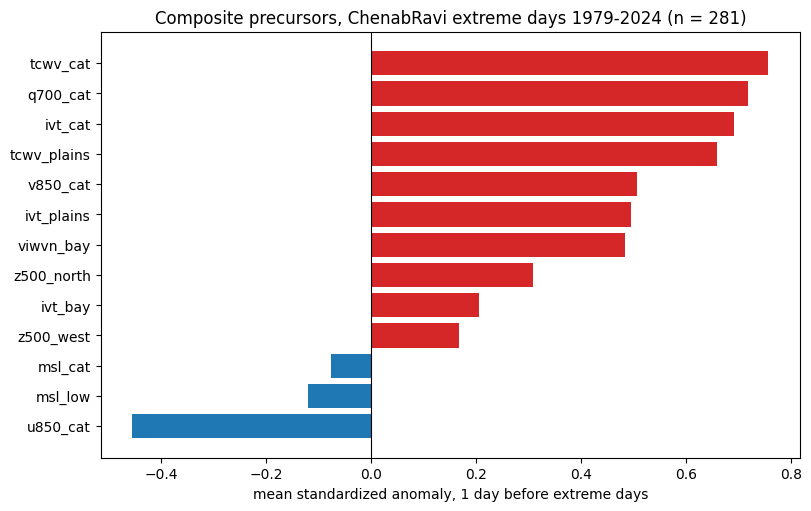

u850_cat_lag1      -0.45
msl_low_lag1       -0.12
msl_cat_lag1       -0.08
z500_west_lag1      0.17
ivt_bay_lag1        0.21
z500_north_lag1     0.31
viwvn_bay_lag1      0.48
ivt_plains_lag1     0.50
v850_cat_lag1       0.51
tcwv_plains_lag1    0.66
ivt_cat_lag1        0.69
q700_cat_lag1       0.72
tcwv_cat_lag1       0.76


In [5]:
tr = table[table.index.year <= 2024]
lag1 = [c_ for c_ in table if c_.endswith('_lag1') and c_ != 'rain_lag1']
z = (tr[lag1] - tr[lag1].mean()) / tr[lag1].std()
comp = z[tr.extreme == 1].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.barh([s.replace('_lag1', '') for s in comp.index], comp.values, color=['tab:red' if v > 0 else 'tab:blue' for v in comp])
ax.axvline(0, color='k', lw=.8); ax.set_xlabel('mean standardized anomaly, 1 day before extreme days')
ax.set_title(f'Composite precursors, {TARGET} extreme days 1979-2024 (n = {int(tr.extreme.sum())})')
plt.savefig(f'{RES}/ml03_composite_lag1.png', dpi=150); plt.show()
print(comp.round(2).to_string())

## Think about it
1. Which 3 variables stand out most the day before extreme days? Does that match what you found for E1 and E2 in your paper?
2. Is the 500 hPa height to the north (ridge) positive or negative? What does that mean physically?